# Web-Nature Only

We use the **web-nature** subset of the **CompCars** dataset (Yang et al., CVPR 2015). we're starting with web-nature only for the first modeling pass and will bring surveillance back in as a separate stream later.

1. Loading and Extraction
2. Web-nature ZIP Extraction
3. Web-nature EDA
4. Quartile Analysis
5. Data Quality & Additional Checks
6. Final Recommendations

> **Note on scope:** colour labels in CompCars only exist for the surveillance-nature subset (`sv_data/color_list.mat`) there is no colour annotation for web-nature images.

### 1. Loading and Exploration of the Dataset

In [1]:
# Install tools needed to unzip the CompCars archive
!apt-get install -y p7zip-full
!pip install patool

import os
import zipfile
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
p7zip-full is already the newest version (16.02+dfsg-8).
0 upgraded, 0 newly installed, 0 to remove and 1 not upgraded.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.0/102.0 kB 4.8 MB/s eta 0:00:00


In [2]:
## Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Confirm the CompCars files are actually visible from Colab

!ls "/content/drive/MyDrive/CompCars"

data.z01  data.z05  data.z09  data.z13	data.z17  data.z21    sv_data.z01
data.z02  data.z06  data.z10  data.z14	data.z18  data.z22    sv_data.z02
data.z03  data.z07  data.z11  data.z15	data.z19  data.zip    sv_data.z03
data.z04  data.z08  data.z12  data.z16	data.z20  README.txt  sv_data.zip


### 2. Web-nature ZIP Extraction

In [4]:
# Unzip the web-nature images from Drive into Colab's local storage.
# Extracting once here
import patoolib
import time

# Always start from a clean folder, had duplication issues
!rm -rf /content/extracted
os.makedirs("/content/extracted", exist_ok=True)

start_time = time.time()

patoolib.extract_archive(
    "/content/drive/MyDrive/CompCars/data.zip",
    outdir="/content/extracted",
    password="d89551fd190e38"
)

elapsed = time.time() - start_time
print(f"\nExtraction took {elapsed:.1f} seconds ({elapsed/60:.1f} minutes)")

INFO patool: Extracting /content/drive/MyDrive/CompCars/data.zip ...
INFO patool: running '/usr/bin/7z' 'x' '-pd89551fd190e38' '-aou' '-o/content/extracted' '--' '/content/drive/MyDrive/CompCars/data.zip'
INFO patool: ... /content/drive/MyDrive/CompCars/data.zip extracted to `/content/extracted'.



Extraction took 767.7 seconds (12.8 minutes)


In [5]:
with open("/content/drive/MyDrive/CompCars/README.txt", "r") as f:
    print(f.read())

This file provides documentation for the CompCars dataset.
(http://mmlab.ie.cuhk.edu.hk/datasets/comp_cars/index.html)

If you use the dataset in your work, please cite our CVPR 2015 paper:
Linjie Yang, Ping Luo, Chen Change Loy, Xiaoou Tang. "A Large-Scale Car Dataset for Fine-Grained Categorization and Verification", In Computer Vision and Pattern Recognition (CVPR), 2015.
 
Descriptions of the folders and files are as follows:

-image:
  Stores all full car images in the path format 'make_id/model_id/released_year/image_name.jpg'.
-label:
  Stores all labels to the full car images in the path format 'make_id/model_id/released_year/image_name.txt'. Each label file has three lines. The first line is a number which is the viewpoint annotation (-1 - uncertain, 1 - front, 2 - rear, 3 - side, 4 - front-side, 5 - rear-side). The second line is the number of the bounding boxes, which is all '1' in the current release. The third line is the coordinates of the bounding box in the format 'x1 y

In [6]:
# CompCars only labels images with number IDs. This file has the actual names ("Audi", "Camry", etc.) matched to those ID numbers.
# We load them here to show real names instead of just numbers.
from scipy.io import loadmat

misc = loadmat("/content/extracted/data/misc/make_model_name.mat")
make_names = [m[0] if len(m) else "" for m in misc['make_names'].flatten()]
model_names = [m[0] if len(m) else "" for m in misc['model_names'].flatten()]

print(make_names[:10])

[np.str_('ABT'), np.str_('BAC'), np.str_('Conquest'), np.str_('DS'), np.str_('Dacia'), np.str_('Fisker'), np.str_('GMC'), np.str_('Gumpert'), np.str_('Hennessey'), np.str_('Icona')]


In [7]:
# Helper function: turns a numeric make_id into its real name ex. "Audi".
def make_id_to_name(make_id):

    return make_names[make_id - 1] if 0 < make_id <= len(make_names) else "Unknown"

In [8]:
DATA_ROOT = "/content/extracted/data"
IMAGE_DIR = f"{DATA_ROOT}/image"

IMG_SIZE = 224  # standard size
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Sanity check: count how many image files exist in the folder,
# to confirm the extraction worked.

def count_images(root_dir, exts=(".jpg", ".jpeg", ".png")):
    total = 0
    for _, _, files in os.walk(root_dir):
        total += sum(1 for f in files if f.lower().endswith(exts))
    return total

web_count = count_images(IMAGE_DIR)

web_count = count_images(IMAGE_DIR)

EXPECTED_WEB_COUNT = 136_726  # known-correct count for the web-nature CompCars subset

assert web_count == EXPECTED_WEB_COUNT, (
    f"Expected {EXPECTED_WEB_COUNT:,} web-nature images but found {web_count:,}. "
    f"Extraction folder likely had leftover files — delete /content/extracted and "
    f"re-run the extraction cell before continuing."
)
print(f"Web-nature images: {web_count:,} — matches expected count.")

Web-nature images: 136,726 — matches expected count.


In [9]:
# Collect every individual image file path.

def collect_paths(root_dir, exts=(".jpg", ".jpeg", ".png")):
    paths = []
    for root, dirs, files in os.walk(root_dir):
        for f in files:
            if f.lower().endswith(exts):
                paths.append(os.path.relpath(os.path.join(root, f), root_dir))
    return paths

web_paths = collect_paths(IMAGE_DIR)

print(f"Collected {len(web_paths):,} web-nature paths")

Collected 136,726 web-nature paths


In [10]:
import pandas as pd

# Turn the list of image file paths into a proper table, one row per image,
# with make/model/year pulled out as their own columns instead of buried in the path string.

def build_web_df(paths, base_dir):
    df = pd.DataFrame({"path": paths})
    df["web_full_path"] = df["path"].apply(lambda p: os.path.join(base_dir, p))

    parts = df["path"].str.split("/")
    df["filename"] = parts.str[-1]
    df["make_id"] = parts.str[0].astype(int)
    df["model_id"] = parts.str[1].astype(int)
    df["year"] = parts.str[2]
    df["make_name"] = df["make_id"].map(make_id_to_name)

    return df

# Build the table, one row per image, with make already attached.
web_df = build_web_df(web_paths, IMAGE_DIR)

print(f"web_df: {len(web_df):,} images, {web_df['make_name'].nunique()} makes")

web_df: 136,726 images, 162 makes


### 3. Web-nature EDA

In [11]:
print(web_df[['path', 'make_id', 'make_name']].head())
print(f"\nNumber of unique makes: {web_df['make_id'].nunique()}")
print(web_df['make_name'].value_counts().head(10))

                              path  make_id make_name
0  102/289/2010/837d25b3411ab6.jpg      102   Peugeot
1  102/289/2010/7689f55738ef1f.jpg      102   Peugeot
2  102/289/2010/282dab819fc283.jpg      102   Peugeot
3  102/289/2010/3287c2f92e8bc4.jpg      102   Peugeot
4  102/289/2010/cf698c9b271486.jpg      102   Peugeot

Number of unique makes: 163
make_name
Volkswagen    5720
Benz          5319
Toyota        4908
Audi          4657
BWM           4531
Ford          3974
Nissan        3831
Hyundai       3786
Chevy         3688
KIA           3220
Name: count, dtype: int64


In [12]:
print(web_df['make_name'].value_counts().tail(10))
print(f"\nMin class size: {web_df['make_name'].value_counts().min()}")
print(f"Max class size: {web_df['make_name'].value_counts().max()}")

make_name
BAC         24
Bufori      23
Carlsson    20
Kombat      17
Huaqi       16
Icona       16
Mazzanti    14
Jinlv       13
Shouwang    11
Huizhong     2
Name: count, dtype: int64

Min class size: 2
Max class size: 5720


In [13]:
web_counts = web_df['make_name'].value_counts()

print("=== Web-Nature Dataset Summary ===")
print(f"Total web-nature images: {len(web_df):,}")
print(f"Number of unique makes: {web_df['make_id'].nunique()}")
print(f"Most common make: {web_counts.idxmax()} ({web_counts.max()} images)")
print(f"Least common make: {web_counts.idxmin()} ({web_counts.min()} images)")
print(f"Class imbalance ratio (max/min): {web_counts.max() / web_counts.min():.1f}x")

=== Web-Nature Dataset Summary ===
Total web-nature images: 136,726
Number of unique makes: 163
Most common make: Volkswagen (5720 images)
Least common make: Huizhong (2 images)
Class imbalance ratio (max/min): 2860.0x


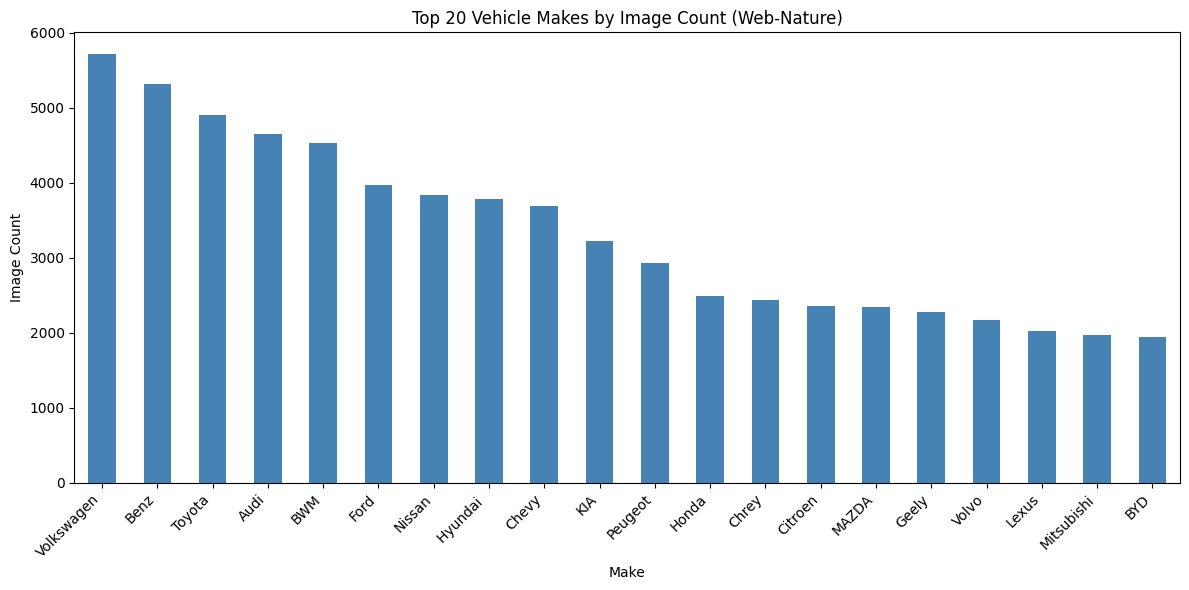

In [14]:
#top 20 makes by image count to make imbalance visible.
top_n = 20
web_counts_top = web_df['make_name'].value_counts().head(top_n)

plt.figure(figsize=(12, 6))
web_counts_top.plot(kind='bar', color='steelblue')
plt.title(f'Top {top_n} Vehicle Makes by Image Count (Web-Nature)')
plt.xlabel('Make')
plt.ylabel('Image Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

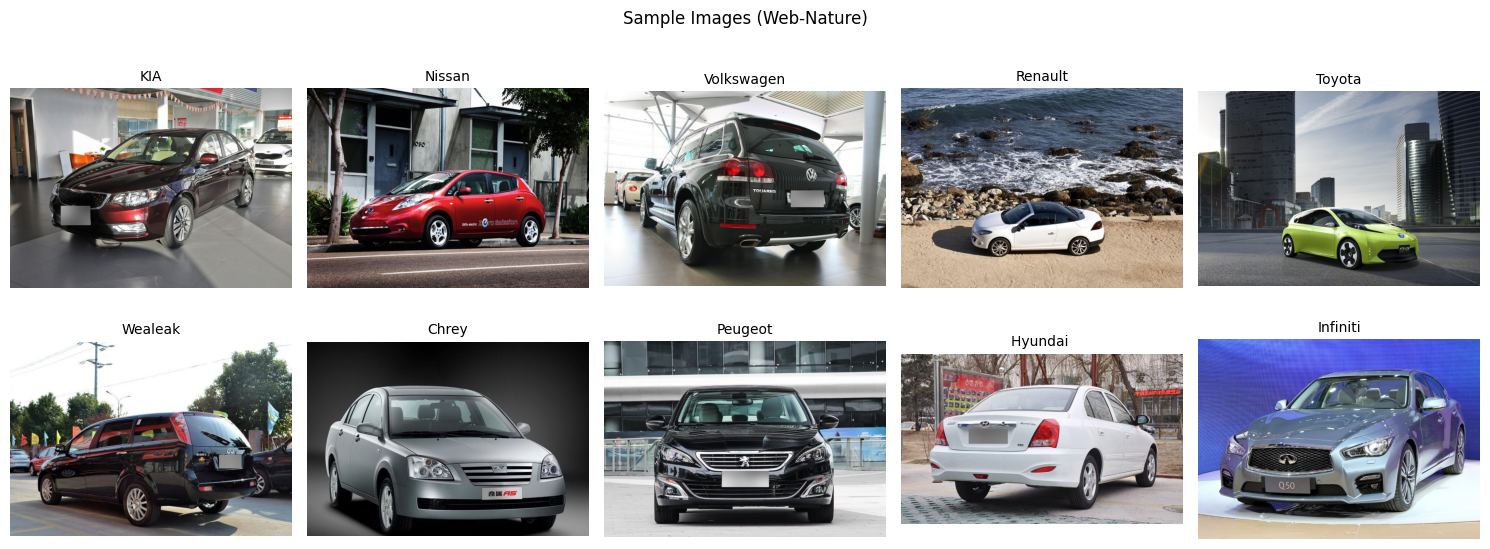

In [15]:
## quick check whether the labels actually look correct.
import random

sample_idx_web = random.sample(range(len(web_df)), 10)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, idx in zip(axes.flat, sample_idx_web):
    row = web_df.iloc[idx]
    img = Image.open(row['web_full_path'])
    ax.imshow(img)
    ax.set_title(row['make_name'], fontsize=10)
    ax.axis('off')
plt.suptitle('Sample Images (Web-Nature)')
plt.tight_layout()
plt.show()

In [16]:
# Check raw image sizes before resizing
sample_dims_web = web_df.groupby('make_name', group_keys=False).apply(
    lambda x: x.sample(min(len(x), 30), random_state=42)
)

dims_web = []
for p in sample_dims_web['web_full_path']:
    with Image.open(p) as img:
        dims_web.append(img.size)

widths_web, heights_web = zip(*dims_web)
print(f"Sampled {len(dims_web)} images across {sample_dims_web['make_name'].nunique()} makes")
print(f"Width range: {min(widths_web)}\u2013{max(widths_web)} px")
print(f"Height range: {min(heights_web)}\u2013{max(heights_web)} px")

/tmp/ipykernel_4428/1542916259.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_dims_web = web_df.groupby('make_name', group_keys=False).apply(


Sampled 4715 images across 162 makes
Width range: 581–1128 px
Height range: 403–1167 px


Web-nature (make distribution)

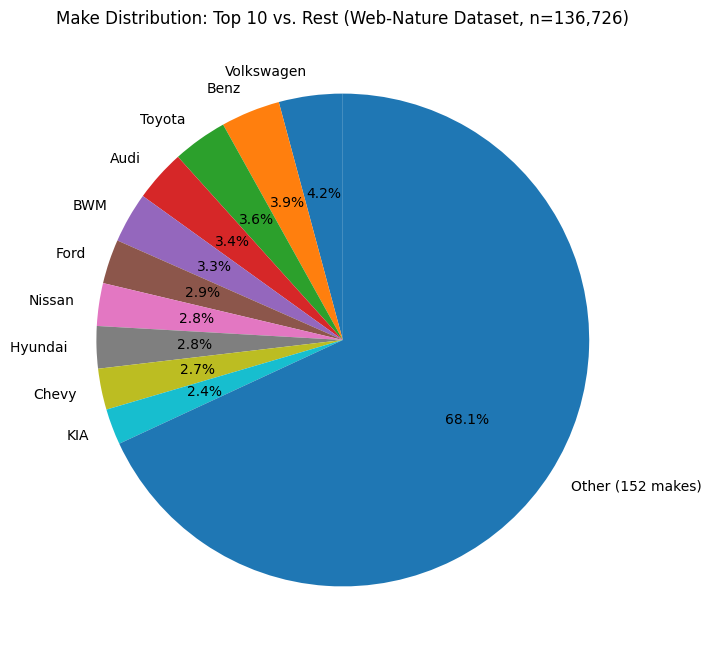

In [17]:
top_n = 10
web_counts = web_df['make_name'].value_counts()
top_10 = web_counts.head(top_n)
other = web_counts.iloc[top_n:].sum()
n_other = web_df['make_name'].nunique() - top_n

pie_data = pd.concat([top_10, pd.Series({f'Other ({n_other} makes)': other})])

plt.figure(figsize=(8, 8))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', startangle=90)
plt.title(f'Make Distribution: Top {top_n} vs. Rest (Web-Nature Dataset, n={len(web_df):,})')
plt.show()

In [18]:
web_counts = web_df['make_name'].value_counts()
other_counts_web = web_counts.iloc[10:]  # everything outside the top 10

print(f"'Other' contains {len(other_counts_web)} makes, {other_counts_web.sum():,} images total")
print(f"\nLargest 'Other' make:  {other_counts_web.idxmax()} ({other_counts_web.max()} images)")
print(f"Smallest 'Other' make: {other_counts_web.idxmin()} ({other_counts_web.min()} images)")
print(f"Median size within 'Other': {other_counts_web.median():.0f} images")
print(f"\nMakes with fewer than 20 images: {(other_counts_web < 20).sum()}")
print(f"Makes with fewer than 5 images:  {(other_counts_web < 5).sum()}")

'Other' contains 152 makes, 93,092 images total

Largest 'Other' make:  Peugeot (2926 images)
Smallest 'Other' make: Huizhong (2 images)
Median size within 'Other': 353 images

Makes with fewer than 20 images: 7
Makes with fewer than 5 images:  1


Cutoff-threshold sensitivity

In [19]:
import numpy as np

web_counts_sorted = web_df['make_name'].value_counts().sort_values()

# Show the distribution of class sizes at different cutoffs
for threshold in [2, 5, 10, 20, 30, 50, 100]:
    n_below = (web_counts_sorted < threshold).sum()
    print(f"Makes with fewer than {threshold} images: {n_below}")

Makes with fewer than 2 images: 0
Makes with fewer than 5 images: 1
Makes with fewer than 10 images: 1
Makes with fewer than 20 images: 7
Makes with fewer than 30 images: 11
Makes with fewer than 50 images: 19
Makes with fewer than 100 images: 29


Full list of Makes

In [20]:
# Full per-make image count table (web-nature only)
web_counts_table = (
    web_df['make_name']
    .value_counts()
    .rename_axis('make_name')
    .reset_index(name='image_count')
    .sort_values('image_count', ascending=False)
    .reset_index(drop=True)
)

print(f"Total makes: {len(web_counts_table)}")
print(f"Total images: {web_counts_table['image_count'].sum():,}\n")

pd.set_option('display.max_rows', None)
display(web_counts_table)

Total makes: 162
Total images: 136,726



,make_name,image_count
0,Volkswagen,5720
1,Benz,5319
2,Toyota,4908
3,Audi,4657
4,BWM,4531
5,Ford,3974
6,Nissan,3831
7,Hyundai,3786
8,Chevy,3688
9,KIA,3220


### 4. Quartile Analysis

In [21]:
web_counts_table['quartile'] = pd.qcut(
    web_counts_table['image_count'],
    q=4,
    labels=['Q1 (fewest)', 'Q2', 'Q3', 'Q4 (most)']
)

print("Quartile boundaries (image count):")
print(web_counts_table['image_count'].quantile([0.25, 0.5, 0.75]).to_string())
print()

quartile_summary = web_counts_table.groupby('quartile', observed=True).agg(
    n_makes=('make_name', 'count'),
    total_images=('image_count', 'sum'),
    min_images=('image_count', 'min'),
    max_images=('image_count', 'max'),
    mean_images=('image_count', 'mean'),
).round(1)

display(quartile_summary)

Quartile boundaries (image count):
0.25     133.75
0.50     416.00
0.75    1065.00



,n_makes,total_images,min_images,max_images,mean_images
quartile,,,,,
Q1 (fewest),41,2656,2,133,64.8
Q2,40,9902,136,410,247.6
Q3,40,26872,422,1050,671.8
Q4 (most),41,97296,1070,5720,2373.1


In [22]:
for q in ['Q1 (fewest)', 'Q2', 'Q3', 'Q4 (most)']:
    subset = web_counts_table[web_counts_table['quartile'] == q].sort_values('image_count')
    print(f"{q} — {len(subset)} makes, {subset['image_count'].sum():,} images total\n")
    display(subset[['make_name', 'image_count']].reset_index(drop=True))
    print()

Q1 (fewest) — 41 makes, 2,656 images total



,make_name,image_count
0,Huizhong,2
1,Shouwang,11
2,Jinlv,13
3,Mazzanti,14
4,Huaqi,16
5,Icona,16
6,Kombat,17
7,Carlsson,20
8,Bufori,23
9,BAC,24



Q2 — 40 makes, 9,902 images total



,make_name,image_count
0,Morgan,136
1,Changhe,139
2,Daihatsu,155
3,Bugatti,161
4,Iveco,162
5,Mitsuoka,165
6,Jonway,167
7,Spyker N.V.,170
8,Wisemann,175
9,Lorinser,175



Q3 — 40 makes, 26,872 images total



,make_name,image_count
0,Beiqiweiwang,422
1,Dacia,424
2,Bentley,476
3,Baojun,491
4,Besturn,509
5,Guangqichuanqi,538
6,Dongfengxiaokang,542
7,Dongnan,543
8,BAW,546
9,Futian,561



Q4 (most) — 41 makes, 97,296 images total



,make_name,image_count
0,Porsche,1070
1,Cadillac,1115
2,Acura,1124
3,Aston Martin,1138
4,Opel,1145
5,Lifan,1176
6,Subaru,1187
7,Zhonghua,1394
8,Yiqi,1420
9,Haima,1424


In [23]:
quartile_colors = {
    'Q1 (fewest)': '#d62728',
    'Q2': '#ff7f0e',
    'Q3': '#1f77b4',
    'Q4 (most)': '#2ca02c',
}

/tmp/ipykernel_4428/3622248203.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(data_by_quartile, labels=quartile_order, patch_artist=True,


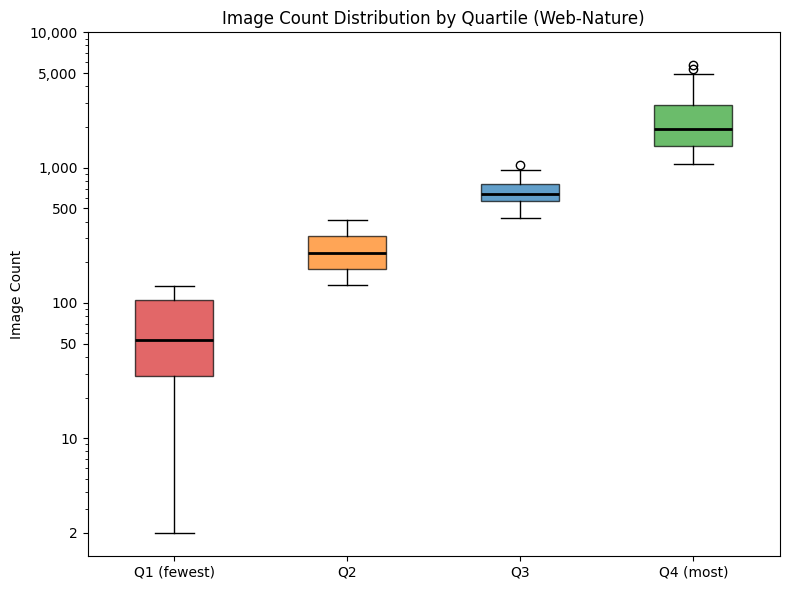

In [24]:
fig, ax = plt.subplots(figsize=(8, 6))

quartile_order = ['Q1 (fewest)', 'Q2', 'Q3', 'Q4 (most)']
data_by_quartile = [
    web_counts_table.loc[web_counts_table['quartile'] == q, 'image_count'].values
    for q in quartile_order
]

box = ax.boxplot(data_by_quartile, labels=quartile_order, patch_artist=True,
                  medianprops=dict(color='black', linewidth=2))

for patch, q in zip(box['boxes'], quartile_order):
    patch.set_facecolor(quartile_colors[q])
    patch.set_alpha(0.7)

ax.set_ylabel('Image Count')
ax.set_title('Image Count Distribution by Quartile (Web-Nature)')
ax.set_yscale('log')

# Log-scale y-axis plain numbers instead of 10^n notation
ax.set_yticks([2, 10, 50, 100, 500, 1000, 5000, 10000])
ax.set_yticklabels(['2', '10', '50', '100', '500', '1,000', '5,000', '10,000'])

plt.tight_layout()
plt.show()

Q1 (red) the makes with the fewest images. The box sits mostly in the 30–100 range, but drops all the way down to 2 images at the worst case. Half of this group has under 50 images, which is thin for a deep learning classifier regardless of where you set your cutoff.

Q2 (orange) roughly 110–430 images per make, median around 230.

Q3 (blue) roughly 450–950 images per make, median around 600, with one make sitting as an outlier near 950.

Q4 (green) the top 40 makes, ranging from about 1,000 up past 5,700 images, with two clear standouts well above the rest of the group (visible as the two circle markers above the box) almost certainly Volkswagen and Toyota, two largest makes from the summary stats.



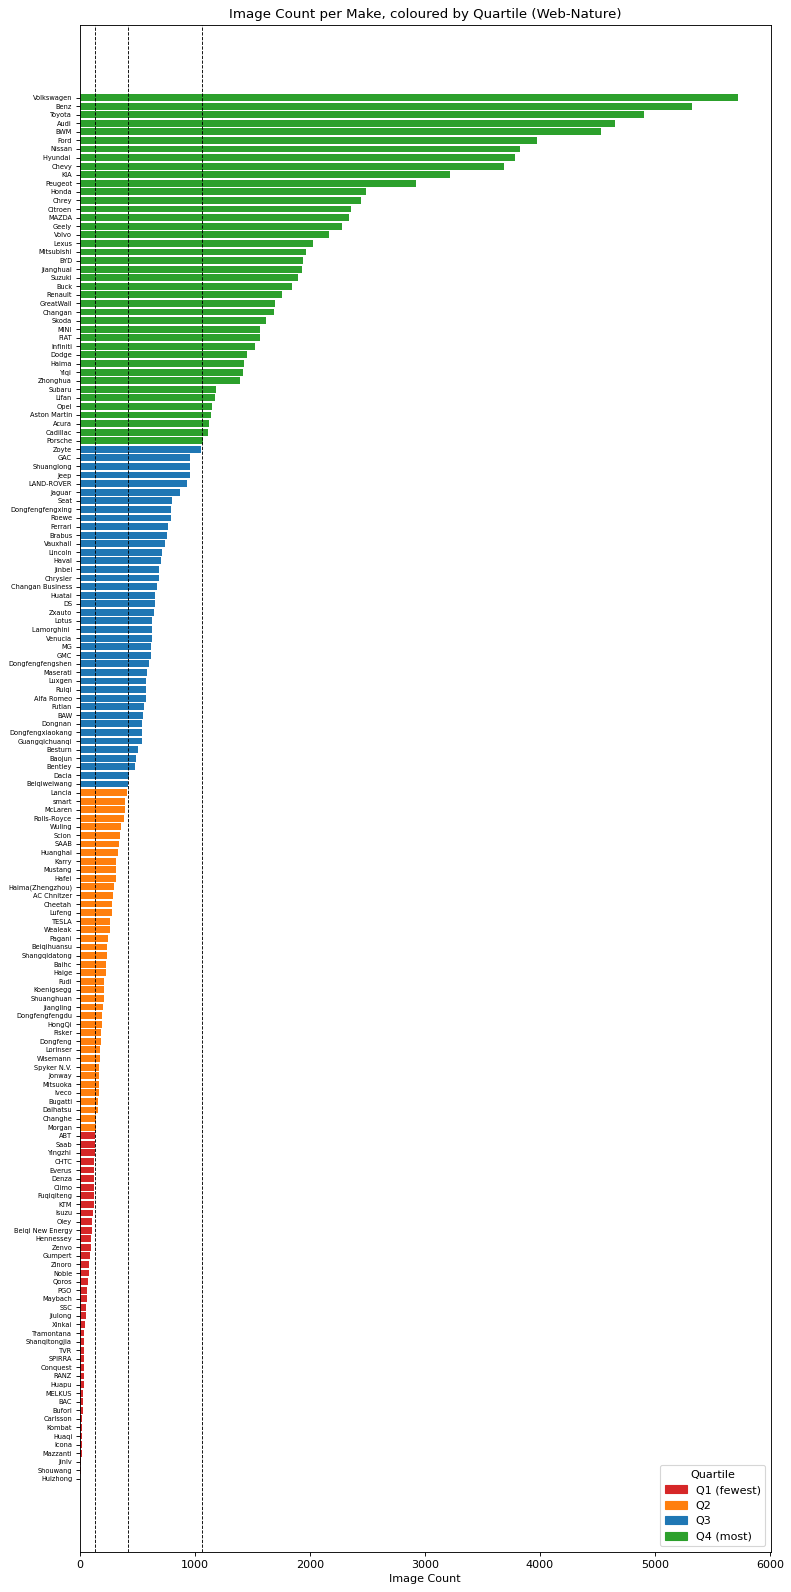

In [25]:
plot_df = web_counts_table.sort_values('image_count', ascending=True)

fig, ax = plt.subplots(figsize=(10, 20), dpi=80)

bar_colors = plot_df['quartile'].map(quartile_colors)
ax.barh(plot_df['make_name'], plot_df['image_count'], color=bar_colors)
ax.tick_params(axis='y', labelsize=6)

for q_val in web_counts_table['image_count'].quantile([0.25, 0.5, 0.75]):
    ax.axvline(q_val, color='black', linestyle='--', linewidth=0.8)

ax.set_xlabel('Image Count')
ax.set_title('Image Count per Make, coloured by Quartile (Web-Nature)')

handles = [plt.Rectangle((0,0),1,1, color=c) for c in quartile_colors.values()]
ax.legend(handles, quartile_colors.keys(), title='Quartile', loc='lower right')

plt.tight_layout()
fig.savefig('/content/web_make_counts_quartile.png', dpi=80, bbox_inches='tight')
plt.close(fig)

from IPython.display import Image as IPyImage, display
display(IPyImage('/content/web_make_counts_quartile.png'))

Load the file that has body-type info

In [26]:
attrs = pd.read_csv(
    f"{DATA_ROOT}/misc/attributes.txt",
    sep=r"\s+",
    names=["model_id", "max_speed", "displacement", "door_number", "seat_number", "type"],
    skiprows=1
)

print(attrs.head())
print(f"\nUnique type codes present: {sorted(attrs['type'].dropna().unique())}")

   model_id  max_speed  displacement  door_number  seat_number  type
0         1        235           1.8            5            5     4
1         2        220           1.8            4            5     3
2         3        228           2.0            4            5     3
3         4        230           2.0            5            5     2
4         5        234           3.0            5            5     2

Unique type codes present: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


In [27]:
with open("/content/drive/MyDrive/CompCars/README.txt", "r") as f:
    print(f.read())

This file provides documentation for the CompCars dataset.
(http://mmlab.ie.cuhk.edu.hk/datasets/comp_cars/index.html)

If you use the dataset in your work, please cite our CVPR 2015 paper:
Linjie Yang, Ping Luo, Chen Change Loy, Xiaoou Tang. "A Large-Scale Car Dataset for Fine-Grained Categorization and Verification", In Computer Vision and Pattern Recognition (CVPR), 2015.
 
Descriptions of the folders and files are as follows:

-image:
  Stores all full car images in the path format 'make_id/model_id/released_year/image_name.jpg'.
-label:
  Stores all labels to the full car images in the path format 'make_id/model_id/released_year/image_name.txt'. Each label file has three lines. The first line is a number which is the viewpoint annotation (-1 - uncertain, 1 - front, 2 - rear, 3 - side, 4 - front-side, 5 - rear-side). The second line is the number of the bounding boxes, which is all '1' in the current release. The third line is the coordinates of the bounding box in the format 'x1 y

In [28]:
from scipy.io import loadmat

car_type_mat = loadmat(f"{DATA_ROOT}/misc/car_type.mat")
print(car_type_mat.keys())

dict_keys(['__header__', '__version__', '__globals__', 'types'])


In [29]:
type_key = [k for k in car_type_mat.keys() if not k.startswith('__')][0]
type_names_raw = car_type_mat[type_key].flatten()
type_names = [t[0] if len(t) else "unknown" for t in type_names_raw]

print(type_names)

[np.str_('MPV'), np.str_('SUV'), np.str_('sedan'), np.str_('hatchback'), np.str_('minibus'), np.str_('fastback'), np.str_('estate'), np.str_('pickup'), np.str_('hardtop convertible'), np.str_('sports'), np.str_('crossover'), np.str_('convertible')]


In [30]:
# map directly to this list's order (index 0 = code 1)
TYPE_MAP = {i + 1: name for i, name in enumerate(type_names)}
TYPE_MAP[0] = "unavailable"

print(TYPE_MAP)

{1: np.str_('MPV'), 2: np.str_('SUV'), 3: np.str_('sedan'), 4: np.str_('hatchback'), 5: np.str_('minibus'), 6: np.str_('fastback'), 7: np.str_('estate'), 8: np.str_('pickup'), 9: np.str_('hardtop convertible'), 10: np.str_('sports'), 11: np.str_('crossover'), 12: np.str_('convertible'), 0: 'unavailable'}


In [31]:
attrs["type_name"] = attrs["type"].map(TYPE_MAP)
print(attrs["type_name"].value_counts(dropna=False))

type_name
unavailable            748
sedan                  290
SUV                    200
hatchback              158
minibus                 71
MPV                     60
sports                  56
pickup                  46
fastback                22
hardtop convertible     22
convertible             16
estate                  14
crossover               13
Name: count, dtype: int64


In [32]:
web_df = web_df.merge(attrs[["model_id", "type_name"]], on="model_id", how="left")

print(f"Matched type labels: {web_df['type_name'].notna().sum():,} / {len(web_df):,}")

# integrity check: as a left-merge on model_id will silently duplicate rows

assert attrs['model_id'].is_unique, (
    f"attributes.txt has duplicate model_id rows "
    f"({attrs['model_id'].duplicated().sum()} dupes) — merge will inflate web_df!"
)
assert len(web_df) == web_count, (
    f"Row count changed after merge: {len(web_df):,} vs expected {web_count:,}. "
    f"Merge likely duplicated rows — investigate before continuing."
)
print(f"Merge integrity OK: web_df still has {len(web_df):,} rows, attrs.model_id is unique.")

Matched type labels: 136,726 / 136,726
Merge integrity OK: web_df still has 136,726 rows, attrs.model_id is unique.


In [33]:
# "unavailable" was being counted as if it were a real shape (like sedan or SUV).
# turn it back into a proper missing value so it doesn't skew shape stats.
n_before = (web_df['type_name'] == 'unavailable').sum()
web_df['type_name'] = web_df['type_name'].replace('unavailable', pd.NA)

print(f"Recoded {n_before:,} 'unavailable' labels to NaN.")
print(f"Actual shape coverage: {web_df['type_name'].notna().sum():,} / {len(web_df):,} "
      f"({web_df['type_name'].notna().mean()*100:.1f}%)")

Recoded 38,884 'unavailable' labels to NaN.
Actual shape coverage: 97,842 / 136,726 (71.6%)


=== Shape (Body Type) Summary ===
Number of unique shapes: 12
Most common: sedan (32274 images)
Least common: crossover (937 images)
Imbalance ratio (max/min): 34.4x


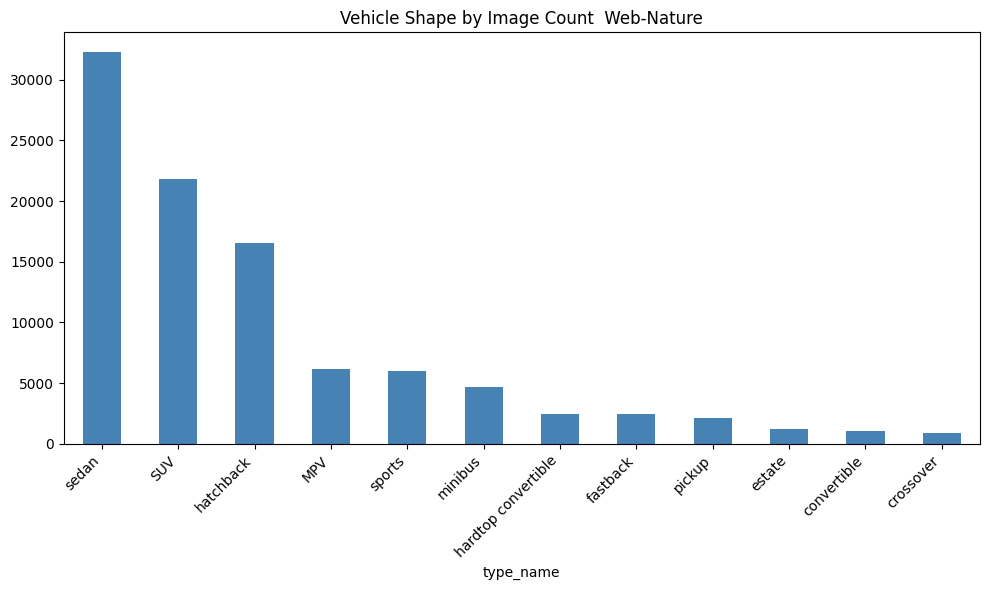

In [34]:
#how many images belong to each shape
shape_counts = web_df['type_name'].value_counts()

print("=== Shape (Body Type) Summary ===")
print(f"Number of unique shapes: {web_df['type_name'].nunique()}")
print(f"Most common: {shape_counts.idxmax()} ({shape_counts.max()} images)")
print(f"Least common: {shape_counts.idxmin()} ({shape_counts.min()} images)")
print(f"Imbalance ratio (max/min): {shape_counts.max() / shape_counts.min():.1f}x")

plt.figure(figsize=(10, 6))
shape_counts.plot(kind='bar', color='steelblue')
plt.title('Vehicle Shape by Image Count  Web-Nature')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [35]:
# Shape imbalance ratio
shape_counts_clean = web_df['type_name'].dropna().value_counts()
print(f"Shape imbalance ratio (max/min): {shape_counts_clean.max() / shape_counts_clean.min():.1f}x")
print(f"Most common shape: {shape_counts_clean.idxmax()} ({shape_counts_clean.max():,} images)")
print(f"Least common shape: {shape_counts_clean.idxmin()} ({shape_counts_clean.min():,} images)")


Shape imbalance ratio (max/min): 34.4x
Most common shape: sedan (32,274 images)
Least common shape: crossover (937 images)


Visual sanity check
do shape labels actually match the images?

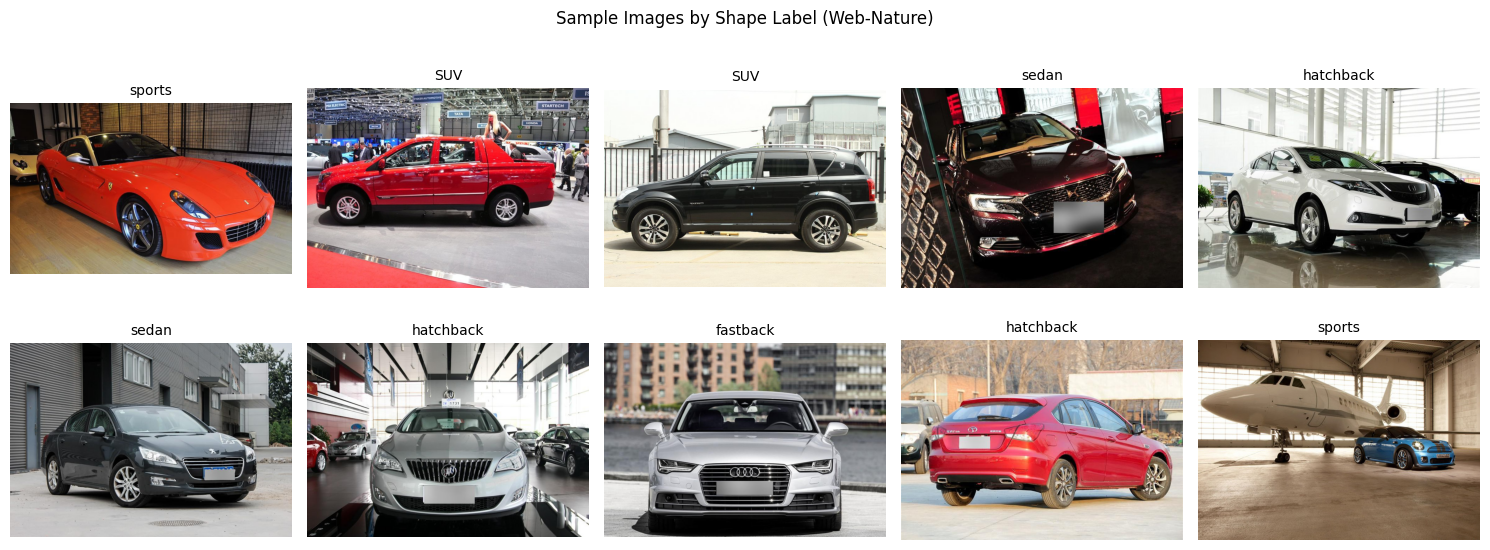

In [36]:
# Catches label-offset or join bugs that a bar chart alone won't reveal.
import random

shape_sample_df = web_df.dropna(subset=['type_name'])
sample_idx_shape = random.sample(range(len(shape_sample_df)), 10)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, idx in zip(axes.flat, sample_idx_shape):
    row = shape_sample_df.iloc[idx]
    img = Image.open(row['web_full_path'])
    ax.imshow(img)
    ax.set_title(row['type_name'], fontsize=10)
    ax.axis('off')
plt.suptitle('Sample Images by Shape Label (Web-Nature)')
plt.tight_layout()
plt.show()


images missing labesl

In [37]:
web_df_with_type_code = web_df.merge(
    attrs[["model_id", "type"]], on="model_id", how="left", suffixes=("", "_raw")
)

coded_unavailable = (web_df_with_type_code["type"] == 0).sum()
join_failed = web_df_with_type_code["type"].isna().sum()
missing_shape = web_df['type_name'].isna().sum()

print(f"Total missing shape label: {missing_shape:,} ({missing_shape/len(web_df)*100:.1f}%)")
print(f"  - genuinely coded 'unavailable' (type=0 in attributes.txt): {coded_unavailable:,}")
print(f"  - model_id had no match in attrs.txt at all (join failure):  {join_failed:,}")

if join_failed > 0:
    missing_model_ids = web_df_with_type_code.loc[
        web_df_with_type_code["type"].isna(), "model_id"
    ].unique()
    print(f"\n{len(missing_model_ids)} distinct model_id(s) never matched — "
          f"first few: {sorted(missing_model_ids)[:10]}")


Total missing shape label: 38,884 (28.4%)
  - genuinely coded 'unavailable' (type=0 in attributes.txt): 38,884
  - model_id had no match in attrs.txt at all (join failure):  0


### 5. Data Quality & Additional Checks

File corrupt OR unreadable images

In [38]:
from PIL import Image
import time

def find_corrupt_images(df):
    bad_files = []
    for path in df['web_full_path']:
        try:
            with Image.open(path) as img:
                img.verify()  # checks the file is a valid, complete image
        except Exception as e:
            bad_files.append((path, str(e)))
    return bad_files

start_time = time.time()
bad_web = find_corrupt_images(web_df)
elapsed = time.time() - start_time

print(f"Corrupt/unreadable web images: {len(bad_web)}")
print(f"Check took {elapsed:.1f} seconds ({elapsed/60:.1f} minutes) for {len(web_df):,} images")

Corrupt/unreadable web images: 0
Check took 141.3 seconds (2.4 minutes) for 136,726 images


Duplicated images

In [39]:
# web_df's row count should still match the original web-nature image count 136,726

assert len(web_df) == web_count, (
    f"web_df has {len(web_df):,} rows but web_count (the original image count) is "
    f"{web_count:,}. web_df was mutated somewhere in this session — do not proceed. "
    f"Restart the kernel and Run All to get back to a clean state."
)
print(f"web_df row count OK: {len(web_df):,} rows, matches web_count.")


web_df row count OK: 136,726 rows, matches web_count.


In [41]:
!pip install imagehash --quiet
import imagehash
from PIL import Image
import time

def find_duplicate_images(df):
    hashes = {}
    total = len(df)
    start_time = time.time()

    for i, path in enumerate(df['web_full_path']):
        if i % 10000 == 0 and i > 0:
            elapsed = time.time() - start_time
            rate = i / elapsed
            remaining = (total - i) / rate
            print(f"Checked {i:,}/{total:,} images... "
                  f"({elapsed/60:.1f} min elapsed, ~{remaining/60:.1f} min remaining)")
        try:
            with Image.open(path) as img:
                fingerprint = str(imagehash.phash(img))
                hashes.setdefault(fingerprint, []).append(path)
        except Exception:
            continue

    duplicates = {fp: paths for fp, paths in hashes.items() if len(paths) > 1}
    return duplicates, time.time() - start_time

web_duplicates, dup_elapsed = find_duplicate_images(web_df)
print(f"\nFound {len(web_duplicates)} duplicate groups in web-nature ({dup_elapsed/60:.1f} min)")

Checked 10,000/136,726 images... (1.8 min elapsed, ~23.4 min remaining)
Checked 20,000/136,726 images... (3.8 min elapsed, ~21.9 min remaining)
Checked 30,000/136,726 images... (5.8 min elapsed, ~20.5 min remaining)
Checked 40,000/136,726 images... (7.7 min elapsed, ~18.6 min remaining)
Checked 50,000/136,726 images... (9.6 min elapsed, ~16.6 min remaining)
Checked 60,000/136,726 images... (11.5 min elapsed, ~14.6 min remaining)
Checked 70,000/136,726 images... (13.3 min elapsed, ~12.7 min remaining)
Checked 80,000/136,726 images... (15.4 min elapsed, ~10.9 min remaining)
Checked 90,000/136,726 images... (17.3 min elapsed, ~9.0 min remaining)
Checked 100,000/136,726 images... (19.2 min elapsed, ~7.0 min remaining)
Checked 110,000/136,726 images... (21.1 min elapsed, ~5.1 min remaining)
Checked 120,000/136,726 images... (23.1 min elapsed, ~3.2 min remaining)
Checked 130,000/136,726 images... (25.1 min elapsed, ~1.3 min remaining)

Found 595 duplicate groups in web-nature (26.4 min)


In [42]:
n_duplicate_images = sum(len(paths) for paths in web_duplicates.values())
print(f"{n_duplicate_images:,} images are involved in {len(web_duplicates)} duplicate groups")

1,199 images are involved in 595 duplicate groups


1,199 images sit inside 595 duplicate groups, averaging just over 2 images per group, so this is mostly pairs, not large clusters. That's consistent with the same photo being scraped or uploaded twice. At 0.9% of the dataset by image count, it's small but not trivial.

Image Mode

In [43]:
def check_image_modes(df, sample_size=5000):
    sample = df.sample(min(sample_size, len(df)), random_state=42)
    modes = []
    for path in sample['web_full_path']:
        try:
            with Image.open(path) as img:
                modes.append(img.mode)
        except Exception:
            modes.append('ERROR')
    return pd.Series(modes).value_counts()

print("Web-nature image modes:")
print(check_image_modes(web_df))

Web-nature image modes:
RGB    5000
Name: count, dtype: int64


All 5,000 sampled images came back as RGB, no grayscale, no palette-mode images, and no read errors. This is a clean result: it means every image already has 3 colour channels.

Full resolution

Full shape of image sizes as histograms if are most images roughly square, wide, or tall?

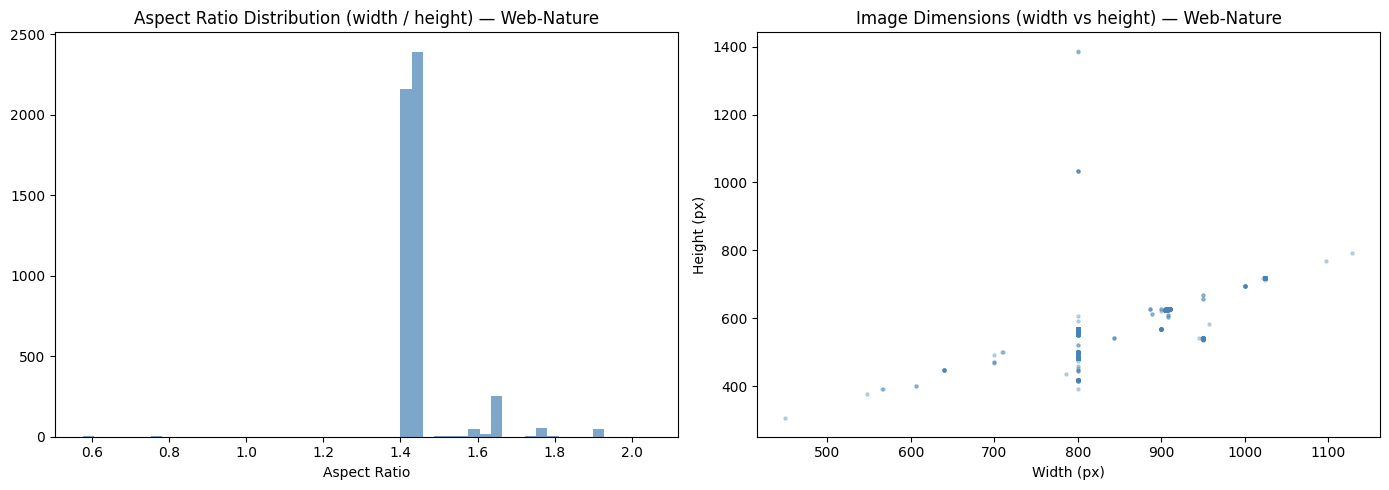

In [44]:
def get_dimensions(df, sample_size=5000):
    sample = df.sample(min(sample_size, len(df)), random_state=42)
    dims = []
    for path in sample['web_full_path']:
        try:
            with Image.open(path) as img:
                w, h = img.size
                dims.append({'width': w, 'height': h, 'aspect_ratio': w / h})
        except Exception:
            continue
    return pd.DataFrame(dims)

web_dims = get_dimensions(web_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(web_dims['aspect_ratio'], bins=50, alpha=0.7, color='steelblue')
axes[0].set_title('Aspect Ratio Distribution (width / height) — Web-Nature')
axes[0].set_xlabel('Aspect Ratio')

axes[1].scatter(web_dims['width'], web_dims['height'], alpha=0.3, s=5, color='steelblue')
axes[1].set_title('Image Dimensions (width vs height) — Web-Nature')
axes[1].set_xlabel('Width (px)')
axes[1].set_ylabel('Height (px)')

plt.tight_layout()
plt.show()

Brightness/sharpness (web-nature baseline)

baseline distribution for web-nature only, useful later as the reference point if/when surveillance images are brought in for a domain-shift comparison.

Web-nature — brightness/sharpness:
        brightness    sharpness
count  2000.000000  2000.000000
mean    120.443202    67.572508
std      29.276515    11.307860
min      16.340240    29.884256
25%     103.125890    60.271110
50%     120.786718    67.011712
75%     139.012861    75.082620
max     223.119969   101.722721


/tmp/ipykernel_4428/2828307901.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([web_quality['brightness']], labels=['Web-nature'])
/tmp/ipykernel_4428/2828307901.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([web_quality['sharpness']], labels=['Web-nature'])


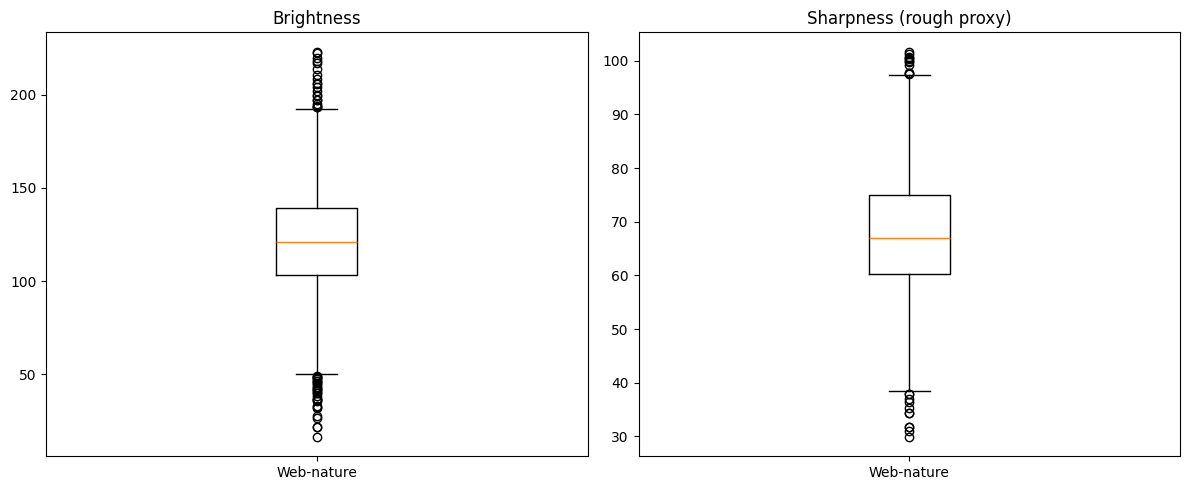

In [45]:
import numpy as np

def image_quality_stats(df, sample_size=2000):
    sample = df.sample(min(sample_size, len(df)), random_state=42)
    stats = []
    for path in sample['web_full_path']:
        try:
            img = Image.open(path).convert('L')
            arr = np.array(img)
            brightness = arr.mean()
            sharpness = arr.std()
            stats.append({'brightness': brightness, 'sharpness': sharpness})
        except Exception:
            continue
    return pd.DataFrame(stats)

web_quality = image_quality_stats(web_df)

print("Web-nature — brightness/sharpness:")
print(web_quality.describe()[['brightness', 'sharpness']])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot([web_quality['brightness']], labels=['Web-nature'])
axes[0].set_title('Brightness')
axes[1].boxplot([web_quality['sharpness']], labels=['Web-nature'])
axes[1].set_title('Sharpness (rough proxy)')
plt.tight_layout()
plt.show()

Brightness: most images cluster around a medium brightness level (median 120), in a fairly narrow band. A handful of images are much brighter (likely white/studio backgrounds) or much darker (shadowed shots) than the rest, but they're a small minority.

Sharpness: most images are reasonably sharp and consistent (median 67), with a small handful of blurrier outliers on the low end.

Overall web-nature images are pretty uniform in quality

Model/year distribution

Number of unique models per make (top 10):
make_name
Volkswagen    67
Toyota        58
Benz          54
Audi          53
BWM           50
Ford          50
Nissan        48
Hyundai       42
Geely         40
Chevy         40
Name: model_id, dtype: int64

Number of unique models per make (bottom 10):
make_name
Maybach          1
Mazzanti         1
SPIRRA           1
Tramontana       1
Shouwang         1
Shanqitongjia    1
Xinkai           1
Yingzhi          1
Zenvo            1
Zinoro           1
Name: model_id, dtype: int64


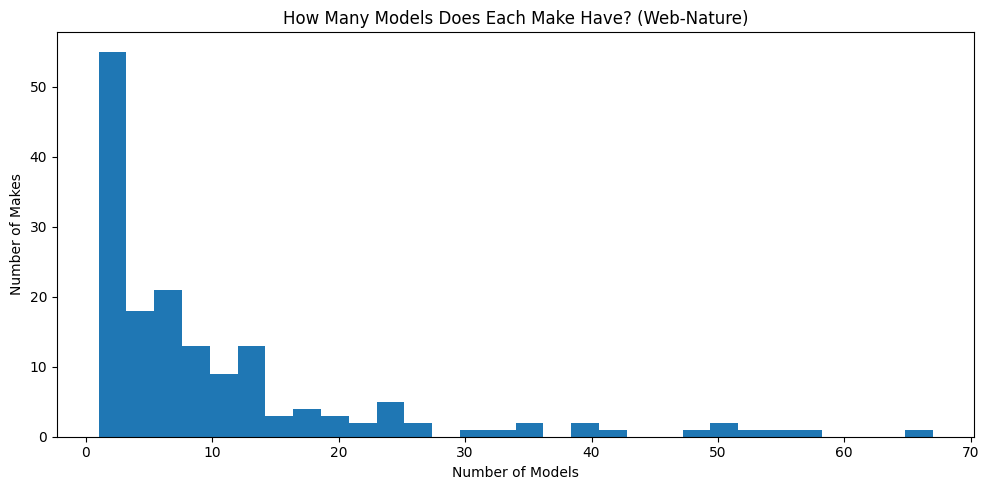

In [46]:
models_per_make = web_df.groupby('make_name')['model_id'].nunique().sort_values(ascending=False)

print("Number of unique models per make (top 10):")
print(models_per_make.head(10))
print("\nNumber of unique models per make (bottom 10):")
print(models_per_make.tail(10))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(models_per_make, bins=30)
ax.set_xlabel('Number of Models')
ax.set_ylabel('Number of Makes')
ax.set_title('How Many Models Does Each Make Have? (Web-Nature)')
plt.tight_layout()
plt.show()

Missing Values

In [47]:
missing_summary = pd.DataFrame({
    'web_df_nulls': web_df.isna().sum(),
})
print(missing_summary)

               web_df_nulls
path                      0
web_full_path             0
filename                  0
make_id                   0
model_id                  0
year                      0
make_name                 0
type_name             38884


Label spelling issues

In [48]:
suspect_makes = ['BWM', 'Chrey']  # typos for BMW and Chery

for name in suspect_makes:
    count = web_counts_table.loc[web_counts_table['make_name'] == name, 'image_count']
    if not count.empty:
        print(f"'{name}' found: {count.values[0]:,} images")

# Look for any other makes possible duplicates/typos
from difflib import get_close_matches
all_makes = web_counts_table['make_name'].tolist()
for make in all_makes:
    close = get_close_matches(make, [m for m in all_makes if m != make], n=2, cutoff=0.8)
    if close:
        print(f"'{make}' looks similar to: {close}")

'BWM' found: 4,531 images
'Chrey' found: 2,440 images
'Chevy' looks similar to: [np.str_('Chrey')]
'Chrey' looks similar to: [np.str_('Chevy')]
'Dongfengfengxing' looks similar to: [np.str_('Dongfengfengshen'), np.str_('Dongfengfengdu')]
'Dongfengfengshen' looks similar to: [np.str_('Dongfengfengxing'), np.str_('Dongfengfengdu')]
'Dongfengfengdu' looks similar to: [np.str_('Dongfengfengxing'), np.str_('Dongfengfengshen')]


Two real spelling issues confirmed: 'BWM' (4,531 images) and 'Chrey' (2,440 images) are typos directly into the dataset's own labels, these are almost certainly meant to be 'BMW' and 'Chery'.

The other three flagged pairs (Dongfengfengxing / Dongfengfengshen / Dongfengfengdu) these are three genuinely different sub-brands under the Dongfeng umbrella that just happen to share a long common prefix, not typos of each other. `difflib`'s cutoff=0.8 is picking up shared characters, not actual spelling errors. No action needed on these three.

Around 6971 (4531+2440) images are currently sitting under the wrong name.

In [49]:
# Compare our make names against CompCars' own official make_names list
official_makes = set(make_names)
our_makes = set(web_df['make_name'].unique())

print("Names in our data but NOT in CompCars' official list:", our_makes - official_makes)

Names in our data but NOT in CompCars' official list: set()


Mismatch in number of makes

In [50]:
# Find any make_id(s) that map to the same make_name as another make_id (a real collision)
id_to_name = web_df[['make_id', 'make_name']].drop_duplicates()
collisions = id_to_name[id_to_name.duplicated('make_name', keep=False)].sort_values('make_name')
print(collisions)

        make_id make_name
69078       133     Lotus
108107      141     Lotus


In [51]:
lotus_ids = [133, 141]

lotus_counts = web_df[web_df['make_id'].isin(lotus_ids)]['make_id'].value_counts()
print(lotus_counts)
print(f"\nTotal Lotus images (combined): {lotus_counts.sum()}")

make_id
141    409
133    221
Name: count, dtype: int64

Total Lotus images (combined): 630


total makes discrepancy: the 163 vs 162 mismatch is 'Lotus', two different make_ids (133 and 141) both mapping to the same make_name.

To fix, we need to decide whether make_id 133 and 141 are genuinely the same brand (almost certainly yes for Lotus) and merge them into a single ID before any modeling step.


Sample images from the Q1 (drop candidate) makes

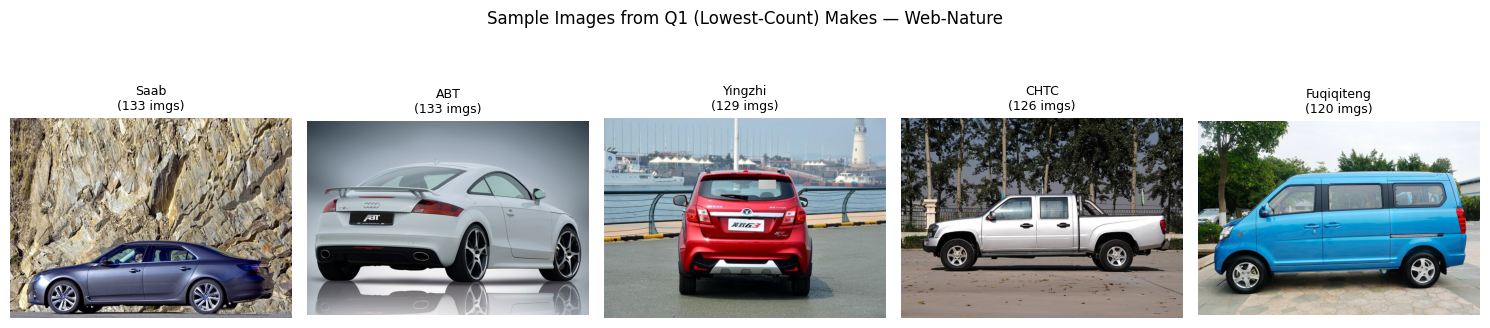

In [52]:
q1_makes = web_counts_table.loc[web_counts_table['quartile'] == 'Q1 (fewest)', 'make_name'].tolist()
sample_q1_makes = q1_makes[:5]  # first 5 for a quick look

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, make in zip(axes, sample_q1_makes):
    row = web_df[web_df['make_name'] == make].iloc[0]
    img = Image.open(row['web_full_path'])
    ax.imshow(img)
    ax.set_title(f"{make}\n({(web_df['make_name'] == make).sum()} imgs)", fontsize=9)
    ax.axis('off')
plt.suptitle('Sample Images from Q1 (Lowest-Count) Makes — Web-Nature')
plt.tight_layout()
plt.show()

### 6. **Issues found**

1. **Make ID collision: Lotus**
   Two different `make_id`s (133 and 141) both map to the name "Lotus".
   
   *Fix:* merge `make_id` 141 & 133 before using `make_id` as a class label. `make_name`-based counts are already correct since they merge automatically.

2. **Label typos: 'BWM' and 'Chrey'**
   4,531 images are labeled "BWM" instead of "BMW," and 2,440 are labeled "Chrey" instead of "Chery." These are misspellings, not different brands.
   
   *Fix:* merge counts under the correct spelling.

3. **Duplicate images: 595 groups, 1,199 images (0.9% of dataset)**
   Perceptual hashing found near-identical images scattered across the dataset, mostly pairs, likely the same photo scraped/uploaded twice.
   
4. **Class imbalance across makes**
   Top make (Volkswagen, 5,700 images) has roughly 2,860x more images than the smallest (2 images). Imbalance is concentrated at the very top, not spread gradually.
   
   *Fix:* drop anything under Q1

5. **Colour not available in this subset**
   Colour labels don't exist for web-nature images (CompCars only labels colour for surveillance-nature)

   
6. **A few extreme image dimension outliers**
   A small number of sampled images have unusually large height (1,150–1,170px) or width (1,100px) compared to the rest, which cluster tightly around fixed sizes.
   
   *Fix:* manually check these few outlier images, confirm they're genuine car photos and not scraping artifacts (such as watermarked assets) before trusting the full sample.
